Created on 25.10.11 to stay organized

In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')

project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *

blues = mpl.colormaps["Blues"]
greens = mpl.colormaps["Greens"]
greys = mpl.colormaps["Greys"]

In [3]:
from matplotlib.colors import LinearSegmentedColormap

c1 = np.array([240, 245, 255]) / 255
c2 = np.array([6, 6, 125]) / 255

# Define the two colors for interpolation
color_start = c1  # Replace with your starting color
color_end = c2     # Replace with your ending color

# Create a custom colormap
blues_custom = LinearSegmentedColormap.from_list("blues_custom", [c1, c2])

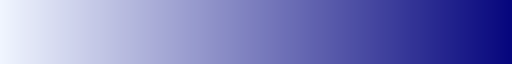

In [4]:
blues_custom

In [5]:
K = 50
N = 93
V_width = 7
V_E_buffer = 0
E_width = 1
setup = (V_width, V_E_buffer, E_width)
stim = "opticflow"
bank_directory = os.path.join(project_folder, 'analyses', 'basis meta neuron bank', 'saved', stim)

## Do DMD

current stimulus is opticflow


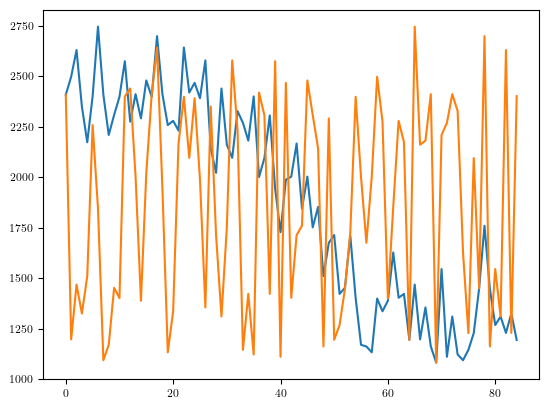

In [ ]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
E = ds.DataNatScenes(data_path, mov_ind=4)
print(f'current stimulus is {E.movname}')
mov_ind = E.mov_ind

# Shuffle trials
rand_perm = np.random.permutation(np.arange(E.N_trials))
trial_shuffled_data = E.data[rand_perm]
D = ds.DataTrialed(trial_shuffled_data)

# View total activity
tot_activity_E = np.array([np.sum(d.X) for d in E.data])
tot_activity_D = np.array([np.sum(d.X) for d in D.data])

# plt.plot(tot_activity_E)
# plt.plot(tot_activity_D)

In [ ]:
tau = E_width + V_E_buffer
tde = V_width - 1

# DMD
D.reset()
D.trim(20)
D.tde(tde)
N_tde = D.N
lam, V = als.dmd(D.X, tau, False)

# DMD on shuffled data
D.reset()
D.trim(20)
# D.shuffle_time()
# D.shuffle_time_uniform()
D.shuffle_time_and_trial()
D.tde(tde)
N_tde = D.N
lam_sh, V_sh = als.dmd(D.X, tau, False)

## Meta neuron modes

In [8]:
def filename(v, b, e, K):
    return f'({v},{b},{e}) K={K}.dat'

load_path = os.path.join(bank_directory, filename(*setup, K))
with open(load_path, 'rb') as f:
    bank_data = pickle.load(f)

In [9]:
basis_vectors = bank_data["basis_vectors"]

modes = []
K_keep = 50
for i in range(K_keep):
    modes.append(basis_vectors[:,i])  # pristine filters

# Overlap plot

In [10]:
def compute_overlap(V):
    W = np.stack(modes[:K], axis=1)
    P = W @ W.T
    mag_a_total = np.sqrt(np.abs(np.diag(np.conj(V.T) @ P @ V)))
    s = np.argsort(mag_a_total)
    return mag_a_total[s]**2, s

In [11]:
Q, s = compute_overlap(V)
Q_sh, s_sh = compute_overlap(V_sh)

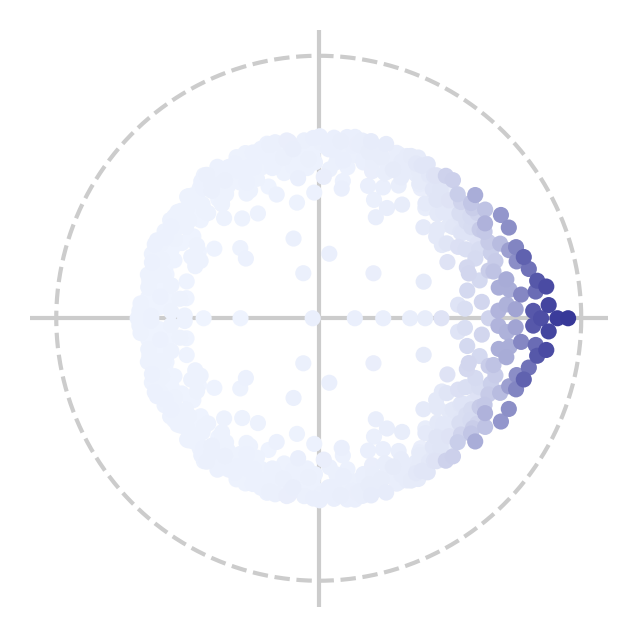

In [ ]:
fig, ax = plt.subplots(dpi=300, figsize = [plot_scale*5, plot_scale*5])
# ax.scatter(x, y, marker='o', color=(0.9,0.9,0.8), s=3)

lw = 1

theta = np.linspace(0,2*np.pi,200)
x, y = np.real(lam), np.imag(lam)
x = x[s]
y = y[s]

ax.plot(np.cos(theta), np.sin(theta), linestyle='--', color=(0.8,0.8,0.8), linewidth=lw)
ax.axhline(0, color=(0.8,0.8,0.8), linewidth=lw)
ax.axvline(0, color=(0.8,0.8,0.8), linewidth=lw)


# colors = blues(Q)
colors = blues_custom(Q)
dots = ax.scatter(x, y, marker='o', c=colors, s=15, zorder=4)

ax.set_aspect('equal')
ax.set_xlim(-1.1,1.1)
ax.set_ylim(-1.1,1.1)
ax.set_xticks([-1,0,1])
ax.set_yticks([-1,0,1])
ax.axis('off')

# plt.savefig('./plots/overlap.png', dpi=3000)

(-1.09986915899354, 1.0999937694758828, -1.099965731583572, 1.099965731583572)

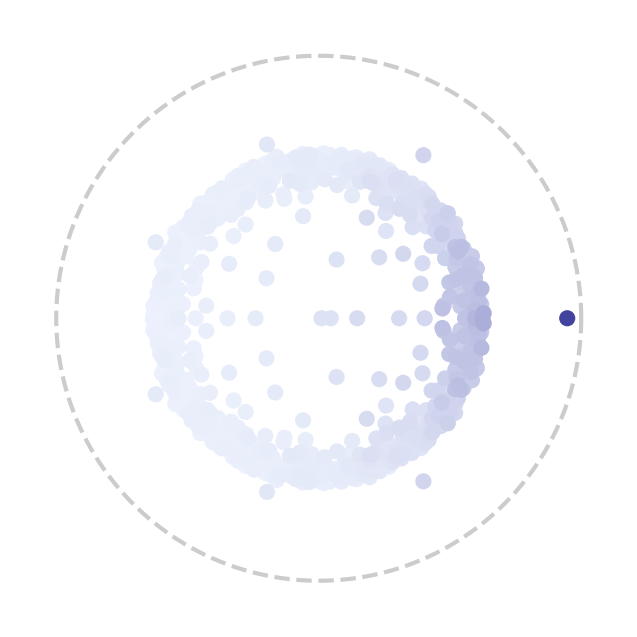

In [13]:
fig, ax = plt.subplots(dpi=300, figsize = [plot_scale*5, plot_scale*5])
# ax.scatter(x, y, marker='o', color=(0.9,0.9,0.8), s=3)

theta = np.linspace(0,2*np.pi,200)
x, y = np.real(lam_sh), np.imag(lam_sh)
x = x[s_sh]
y = y[s_sh]

# colors = blues(Q)
colors = blues_custom(Q_sh)
dots = ax.scatter(x, y, marker='o', c=colors, s=15)
ax.plot(np.cos(theta), np.sin(theta), '--', color=(0.8,0.8,0.8), linewidth=1)
ax.set_aspect('equal')

ax.axis('off')

# plt.savefig('./plots/overlap shuffle time.png', dpi=3000)
# plt.savefig('./plots/overlap shuffle time uniform.png', dpi=3000)

#### Colorbar plot

# Insets for timescale plot

/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_62943/821071107.py:16: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  dots = ax.scatter(x, y, marker='o', c=colors, s=20, zorder=4)


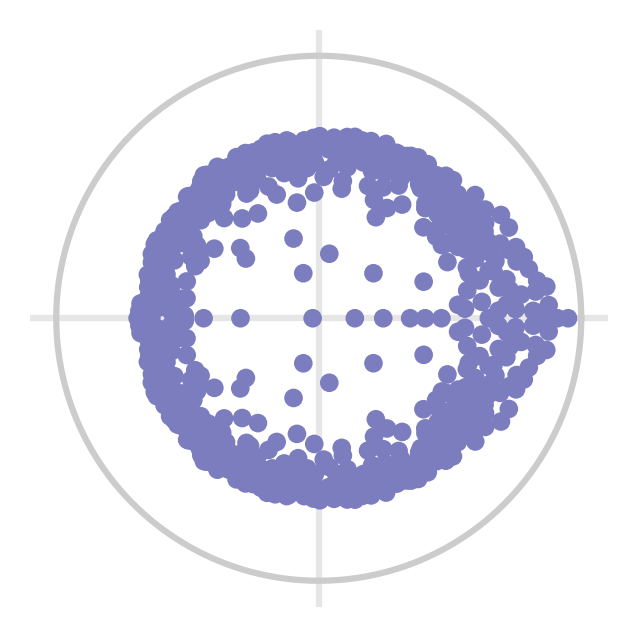

In [20]:
fig, ax = plt.subplots(dpi=300, figsize = [plot_scale*5, plot_scale*5])
# ax.scatter(x, y, marker='o', color=(0.9,0.9,0.8), s=3)

theta = np.linspace(0,2*np.pi,200)
x, y = np.real(lam), np.imag(lam)
x = x[s]
y = y[s]


ax.axhline(0, color=(0.9,0.9,0.9))
ax.axvline(0, color=(0.9,0.9,0.9))
ax.plot(np.cos(theta), np.sin(theta), color=(0.8,0.8,0.8))
# colors = blues(Q)
# colors = blues(0.5)
colors = blues_custom(0.5)
dots = ax.scatter(x, y, marker='o', c=colors, s=20, zorder=4)
ax.set_aspect('equal')


ax.set_xlim(-1.1,1.1)
ax.set_ylim(-1.1,1.1)
ax.axis('off')

plt.savefig('./plots/timescale inset full', dpi=3000)


/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_62943/1572491535.py:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  dots = ax.scatter(x, y, marker='o', c=colors, s=20)


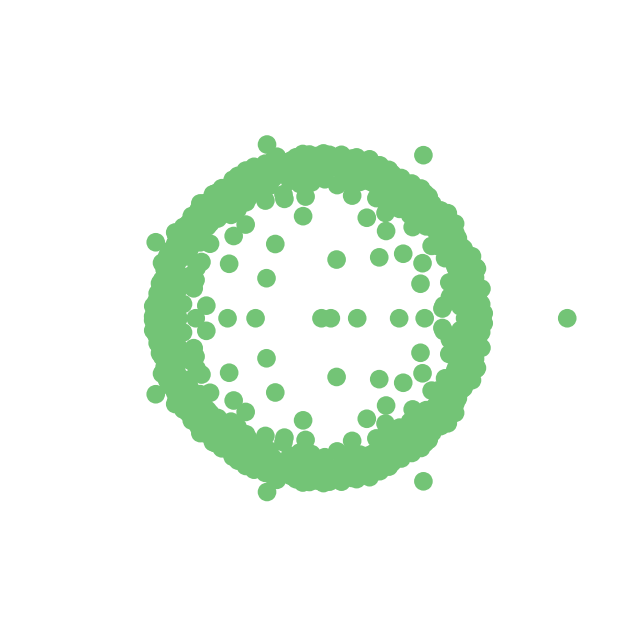

In [21]:
fig, ax = plt.subplots(dpi=300, figsize = [plot_scale*5, plot_scale*5])
# ax.scatter(x, y, marker='o', color=(0.9,0.9,0.8), s=3)

theta = np.linspace(0,2*np.pi,200)
x, y = np.real(lam_sh), np.imag(lam_sh)
x = x[s_sh]
y = y[s_sh]

colors = greens(0.5)
dots = ax.scatter(x, y, marker='o', c=colors, s=20)
ax.set_aspect('equal')
ax.set_xlim(-1.1,1.1)
ax.set_ylim(-1.1,1.1)
ax.axis('off')

plt.savefig('./plots/timescale inset shuffled', dpi=3000)

/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_62943/1743854024.py:16: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  dots = ax.scatter(x, y, marker='o', c=colors, s=20, zorder=4)
/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_62943/1743854024.py:24: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  dots = ax.scatter(x, y, marker='o', c=colors, s=20, zorder=5)


(-1.1, 1.1, -1.1, 1.1)

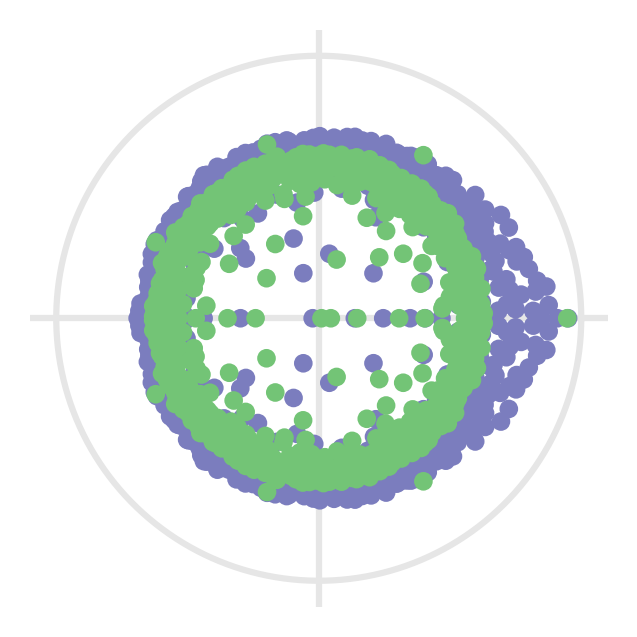

In [25]:
fig, ax = plt.subplots(dpi=300, figsize = [plot_scale*5, plot_scale*5])
# ax.scatter(x, y, marker='o', color=(0.9,0.9,0.8), s=3)

theta = np.linspace(0,2*np.pi,200)
x, y = np.real(lam), np.imag(lam)
x = x[s]
y = y[s]


ax.axhline(0, color=(0.9,0.9,0.9))
ax.axvline(0, color=(0.9,0.9,0.9))
ax.plot(np.cos(theta), np.sin(theta), color=(0.9,0.9,0.9) )
# colors = blues(Q)
# colors = blues(0.5)
colors = blues_custom(0.5)
dots = ax.scatter(x, y, marker='o', c=colors, s=20, zorder=4)
ax.set_aspect('equal')

x, y = np.real(lam_sh), np.imag(lam_sh)
x = x[s_sh]
y = y[s_sh]

colors = greens(0.5)
dots = ax.scatter(x, y, marker='o', c=colors, s=20, zorder=5)
ax.set_aspect('equal')
ax.set_xlim(-1.1,1.1)
ax.set_ylim(-1.1,1.1)
# ax.set_xlim(-1,1)
# ax.set_ylim(-1,1)
ax.axis('off')



# plt.savefig('./plots/timescale inset combo', dpi=3000)
